<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/practices/Nocode_tools.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Cross-Validation & Hyperparameter Tuning**

In [15]:
! pip install mglearn -q

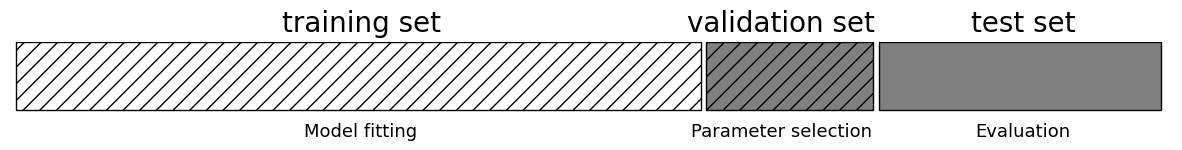

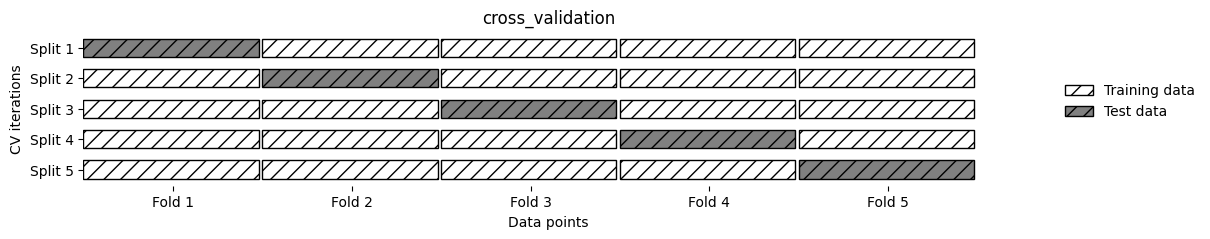

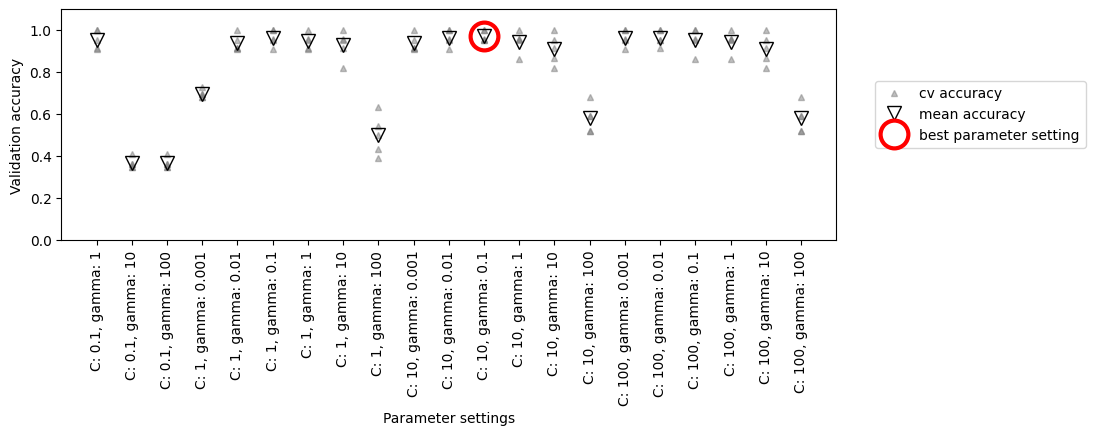

In [20]:
import mglearn

mglearn.plots.plot_threefold_split()
mglearn.plots.plot_cross_validation()
mglearn.plots.plot_cross_val_selection()

# **1. [PyCaret 3.0 | Docs](https://pycaret.gitbook.io/docs)**

In [1]:
!pip install -q uv
!uv venv /content/pc311 --python 3.11
!uv pip install --python /content/pc311/bin/python pycaret
!uv pip install --python /content/pc311/bin/python six

Using CPython 3.11.18
Creating virtual environment at: pc311
? A virtual environment already exists at `pc311`. Do you want to replace it? [y/n] › yes

✔ A virtual environment already exists at `pc311`. Do you want to replace it? · yes
Activate with: source pc311/bin/activate
Using Python 3.11.18 environment at: pc311
Resolved 106 packages in 712ms
Installed 106 packages in 521ms
 + annotated-types==0.8.0
 + asttokens==3.0.2
 + attrs==26.1.0
 + blinker==1.9.0
 + category-encoders==2.7.0
 + certifi==2026.10.23
 + charset-normalizer==3.5.2
 + choreographer==1.4.0
 + click==8.5.1
 + cloudpickle==3.1.2
 + comm==0.2.3
 + contourpy==1.3.3
 + cycler==0.12.1
 + cython==3.3.1
 + dash==4.5.0
 + deprecation==2.1.0
 + executing==2.3.0
 + fastjsonschema==2.22.3
 + flask==3.1.3
 + fonttools==4.68.0
 + formulaic==1.2.2
 + idna==3.20
 + imbalanced-learn==0.14.2
 + importlib-metadata==10.2.0
 + interface-meta==2.0.1
 + ipython==9.18.1
 + ipython-pygments-lexers==1.1.1
 + ipywidgets==8.1.9
 + itsdangero

In [2]:
%%writefile run_pc.py
from pycaret.datasets import get_data
data = get_data('juice')
print(data.head())

Overwriting run_pc.py


In [3]:
!/content/pc311/bin/python run_pc.py

   Id Purchase  WeekofPurchase  ...  PctDiscCH  ListPriceDiff  STORE
0   1       CH             237  ...   0.000000           0.24      1
1   2       CH             239  ...   0.000000           0.24      1
2   3       CH             245  ...   0.091398           0.23      1
3   4       MM             227  ...   0.000000           0.00      1
4   5       CH             228  ...   0.000000           0.00      0

[5 rows x 19 columns]
   Id Purchase  WeekofPurchase  ...  PctDiscCH  ListPriceDiff  STORE
0   1       CH             237  ...   0.000000           0.24      1
1   2       CH             239  ...   0.000000           0.24      1
2   3       CH             245  ...   0.091398           0.23      1
3   4       MM             227  ...   0.000000           0.00      1
4   5       CH             228  ...   0.000000           0.00      0

[5 rows x 19 columns]


In [4]:
%%writefile run_pc.py
from pycaret.datasets import get_data
from pycaret.classification import ClassificationExperiment

data = get_data('diabetes')

s = ClassificationExperiment()
s.setup(data, target='Class variable', session_id=123, html=False)

best = s.compare_models()

# 비교 결과 표를 DataFrame으로 꺼내 저장
results = s.pull()
results.to_csv('compare_results.csv')
display(results)

# 최종 모델 학습 및 저장
final = s.finalize_model(best)
s.save_model(final, 'diabetes_best')
print(best)


Overwriting run_pc.py


In [5]:
!/content/pc311/bin/python run_pc.py

   Number of times pregnant  ...  Class variable
0                         6  ...               1
1                         1  ...               0
2                         8  ...               1
3                         1  ...               0
4                         0  ...               1

[5 rows x 9 columns]
                    Description             Value
0                    Session id               123
1                        Target    Class variable
2                   Target type            Binary
3           Original data shape          (768, 9)
4        Transformed data shape          (768, 9)
5   Transformed train set shape          (537, 9)
6    Transformed test set shape          (231, 9)
7              Numeric features                 8
8                    Preprocess              True
9               Imputation type            simple
10           Numeric imputation              mean
11       Categorical imputation              mode
12               Fold Generator   

In [6]:
import pandas as pd
pd.read_csv('compare_results.csv')

,Unnamed: 0,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
0,lr,Logistic Regression,0.7689,0.8047,0.5602,0.7208,0.6279,0.4641,0.4736,0.811
1,ridge,Ridge Classifier,0.7670,0.8060,0.5497,0.7235,0.6221,0.4581,0.4690,0.054
2,lda,Linear Discriminant Analysis,0.7670,0.8055,0.5550,0.7202,0.6243,0.4594,0.4695,0.046
3,rf,Random Forest Classifier,0.7485,0.7911,0.5284,0.6811,0.5924,0.4150,0.4238,0.220
4,nb,Naive Bayes,0.7427,0.7955,0.5702,0.6543,0.6043,0.4156,0.4215,0.092
5,gbc,Gradient Boosting Classifier,0.7373,0.7909,0.5550,0.6445,0.5931,0.4013,0.4059,0.172
6,ada,Ada Boost Classifier,0.7372,0.7799,0.5275,0.6585,0.5796,0.3926,0.4017,0.118
7,et,Extra Trees Classifier,0.7299,0.7788,0.4965,0.6516,0.5596,0.3706,0.3802,0.192
8,qda,Quadratic Discriminant Analysis,0.7282,0.7894,0.5281,0.6558,0.5736,0.3785,0.3910,0.027
9,lightgbm,Light Gradient Boosting Machine,0.7133,0.7645,0.5398,0.6036,0.5650,0.3534,0.3580,0.390


In [7]:
%%writefile run_pc_lgbm.py
from pycaret.datasets import get_data
from pycaret.classification import ClassificationExperiment

data = get_data('diabetes')

s = ClassificationExperiment()
s.setup(data, target='Class variable', session_id=123, html=False)

# 1) 모델 비교 (전체)
best = s.compare_models()
compare_results = s.pull()
compare_results.to_csv('compare_results.csv')
print(compare_results)

# 2) 비교한 모델 중 LightGBM만 선택 (1위가 아니어도 lightgbm을 생성)
lgbm = s.create_model('lightgbm')
base_results = s.pull()
base_results.to_csv('lgbm_base_cv.csv')
print(base_results)

# 3) LightGBM만 튜닝 (Optuna 없이 기본 탐색 사용)
tuned = s.tune_model(
    lgbm,
    optimize='AUC',
    n_iter=50,
    choose_better=True,   # 튜닝 결과가 더 나쁘면 원래 모델 유지
)
tuned_results = s.pull()
tuned_results.to_csv('lgbm_tuned_cv.csv')
print(tuned_results)
print(tuned)

# 4) 홀드아웃 세트 평가
s.predict_model(tuned)
print(s.pull())

# 5) 그래프는 파일로 저장
s.plot_model(tuned, plot='auc', save=True)
s.plot_model(tuned, plot='feature', save=True)

# 6) 최종 학습 후 저장
final = s.finalize_model(tuned)
s.save_model(final, 'lgbm_tuned')

Overwriting run_pc_lgbm.py


In [8]:
!/content/pc311/bin/python run_pc_lgbm.py

   Number of times pregnant  ...  Class variable
0                         6  ...               1
1                         1  ...               0
2                         8  ...               1
3                         1  ...               0
4                         0  ...               1

[5 rows x 9 columns]
                    Description             Value
0                    Session id               123
1                        Target    Class variable
2                   Target type            Binary
3           Original data shape          (768, 9)
4        Transformed data shape          (768, 9)
5   Transformed train set shape          (537, 9)
6    Transformed test set shape          (231, 9)
7              Numeric features                 8
8                    Preprocess              True
9               Imputation type            simple
10           Numeric imputation              mean
11       Categorical imputation              mode
12               Fold Generator   

# **2. [Optuna - A hyperparameter optimization framework](https://optuna.org/)**

In [9]:
 ! pip install optuna -q

In [10]:
import pandas as pd
import optuna
import lightgbm as lgb
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

# 1. 데이터 로드 (내장 유방암 데이터셋 기준)
cancer = load_breast_cancer(as_frame=True)
X = cancer.data
y = cancer.target

# 2. 학습/테스트 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=123
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

# 3. Optuna 목적 함수 정의
def objective(trial):
    params = {
        "objective": "binary",
        "metric": "auc",
        "verbosity": -1,
        "random_state": 123,
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
    }

    model = lgb.LGBMClassifier(**params)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    return scores.mean()

# 4. 최적화 실행
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=123))
study.optimize(objective, n_trials=50)

print(f"Best CV ROC-AUC: {study.best_value:.4f}")
print("Best Params:", study.best_params)

# 5. 최적 파라미터로 최종 모델 학습 및 테스트 평가
best_model = lgb.LGBMClassifier(
    **study.best_params,
    objective="binary",
    random_state=123,
    verbosity=-1
)
best_model.fit(X_train, y_train)

y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, y_pred_proba)
print(f"Test ROC-AUC: {test_auc:.4f}")

Best CV ROC-AUC: 0.9959
Best Params: {'n_estimators': 870, 'learning_rate': 0.06136117908019485, 'num_leaves': 31, 'max_depth': 6, 'min_child_samples': 41, 'subsample': 0.6639846793968683, 'colsample_bytree': 0.6022664461181508, 'reg_alpha': 0.0001153120132234733, 'reg_lambda': 7.727075453565244e-08}
Test ROC-AUC: 0.9997


# **3. [Welcome to Lazy Predict](https://lazypredict.readthedocs.io/en/latest/index.html#welcome-to-lazy-predict)**

In [11]:
pip install lazypredict -q

In [12]:
from lazypredict.Supervised import LazyClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
data = load_breast_cancer()
X = data.data
y= data.target
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=.5,random_state =123)
clf = LazyClassifier(verbose=0,ignore_warnings=True, custom_metric=None)
models,predictions = clf.fit(X_train, X_test, y_train, y_test)
models

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
LinearSVC,0.989474,0.987544,0.992478,0.989462,0.989478,0.989474,0.154648
Perceptron,0.985965,0.984797,0.993225,0.985965,0.985965,0.985965,0.138294
LogisticRegression,0.985965,0.982690,0.994719,0.985934,0.986010,0.985965,0.303503
SVC,0.982456,0.979942,0.994879,0.982437,0.982445,0.982456,0.057670
LabelPropagation,0.975439,0.974448,NaN,0.975464,0.975515,0.975439,0.153952
LabelSpreading,0.975439,0.974448,NaN,0.975464,0.975515,0.975439,0.240280
XGBClassifier,0.975439,0.974448,0.987411,0.975464,0.975515,0.975439,0.599949
BaggingClassifier,0.971930,0.973808,0.986024,0.972041,0.972559,0.971930,0.136962
PassiveAggressiveClassifier,0.978947,0.972981,0.996213,0.978853,0.979183,0.978947,0.183493


# **4. [AutoGluon](https://auto.gluon.ai/stable/index.html)**

- 교차검증을 하지 않음(대규모 데이터인 경우)
-  Train(개별 모델 학습) $\rightarrow$ Validation(모델 선택 및 앙상블 가중치 결정) $\rightarrow$ Test(최종 성적 산출)
- 앙상블 stacking 알고리즘 적용

In [22]:
!pip install autogluon -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [23]:
from autogluon.tabular import TabularDataset, TabularPredictor

In [24]:
data_url = 'https://raw.githubusercontent.com/mli/ag-docs/main/knot_theory/'
train_data = TabularDataset(f'{data_url}train.csv')
train_data.head()

,Unnamed: 0,chern_simons,cusp_volume,hyperbolic_adjoint_torsion_degree,hyperbolic_torsion_degree,injectivity_radius,longitudinal_translation,meridinal_translation_imag,meridinal_translation_real,short_geodesic_imag_part,short_geodesic_real_part,Symmetry_0,Symmetry_D3,Symmetry_D4,Symmetry_D6,Symmetry_D8,Symmetry_Z/2 + Z/2,volume,signature
0,70746,0.090530,12.226322,0,10,0.507756,10.685555,1.144192,-0.519157,-2.760601,1.015512,0.0,0.0,0.0,0.0,0.0,1.0,11.393225,-2
1,240827,0.232453,13.800773,0,14,0.413645,10.453156,1.320249,-0.158522,-3.013258,0.827289,0.0,0.0,0.0,0.0,0.0,1.0,12.742782,0
2,155659,-0.144099,14.761030,0,14,0.436928,13.405199,1.101142,0.768894,2.233106,0.873856,0.0,0.0,0.0,0.0,0.0,0.0,15.236505,2
3,239963,-0.171668,13.738019,0,22,0.249481,27.819496,0.493827,-1.188718,-2.042771,0.498961,0.0,0.0,0.0,0.0,0.0,0.0,17.279890,-8
4,90504,0.235188,15.896359,0,10,0.389329,15.330971,1.036879,0.722828,-3.056138,0.778658,0.0,0.0,0.0,0.0,0.0,0.0,16.749298,4


label = 'signature'

사용자가 직접 데이터 타입을 고치지 않아도 AutoGluon이 알아서 올바른 타입과 문제 유형으로 수정해 처리

In [25]:
label = 'signature'
train_data[label].describe()

,signature
count,10000.000000
mean,-0.022000
std,3.025166
min,-12.000000
25%,-2.000000
50%,0.000000
75%,2.000000
max,12.000000


In [26]:
predictor = TabularPredictor(label=label).fit(train_data)

No path specified. Models will be saved in: "AutogluonModels/ag-20261116_053154"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.18
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Oct 22 03:07:54 UTC 2026
CPU Count:          2
Pytorch Version:    2.13.0+cu130
CUDA Version:       CUDA is not available
Memory Avail:       10.67 GB / 12.67 GB (84.2%)
Disk Space Avail:   98.19 GB / 107.72 GB (91.2%)
No presets specified! To achieve strong results with AutoGluon, it is recommended to use the available presets. Defaulting to `'medium'`...
	Recommended Presets (For more details refer to https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html#presets):
	presets='extreme'  : Use this if you have a GPU. The go-to preset for best results, and the one to use for benchmark comparisons. New in v1.6: far better than 'best' on datasets <100000 samples by using Tabul

In [30]:
predictor

In [31]:
# 학습 데이터 검증 점수 기준 리더보드
predictor.leaderboard()

,model,score_val,eval_metric,pred_time_val,fit_time,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,0.961962,accuracy,0.324854,25.117537,0.001162,0.132783,2,True,12
1,CatBoost,0.955956,accuracy,0.038572,75.377109,0.038572,75.377109,1,True,6
2,LightGBM,0.955956,accuracy,0.174434,7.747341,0.174434,7.747341,1,True,3
3,XGBoost,0.954955,accuracy,0.026349,8.892468,0.026349,8.892468,1,True,9
4,RandomForestEntr,0.949950,accuracy,0.109411,11.881333,0.109411,11.881333,1,True,5
5,LightGBMLarge,0.949950,accuracy,0.461750,16.212790,0.461750,16.212790,1,True,11
6,NeuralNetTorch,0.948949,accuracy,0.016053,166.946124,0.016053,166.946124,1,True,10
7,ExtraTreesGini,0.946947,accuracy,0.129240,3.482256,0.129240,3.482256,1,True,7
8,LightGBMXT,0.945946,accuracy,0.224502,8.325661,0.224502,8.325661,1,True,2
9,RandomForestGini,0.944945,accuracy,0.110921,6.754579,0.110921,6.754579,1,True,4


In [33]:
print("문제 유형:", predictor.problem_type)       # multiclass, binary, regression 등
print("평가지표:", predictor.eval_metric)         # accuracy, roc_auc 등
print("타겟 컬럼:", predictor.label)              # 'signature' 등
print("클래스 목록:", predictor.class_labels)     # 분류 문제일 때 정답 라벨 목록
print("최고 성능 모델:", predictor.model_best)    # 예측 시 기본으로 사용되는 최적 모델명
print("학습된 모든 모델:", predictor.model_names()) # 학습된 전체 모델 이름 리스트
print("모델 저장 경로:", predictor.path)          # 로컬에 저장된 폴더 위치

문제 유형: multiclass
평가지표: accuracy
타겟 컬럼: signature
클래스 목록: [-12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12]
최고 성능 모델: WeightedEnsemble_L2
학습된 모든 모델: ['NeuralNetFastAI', 'LightGBMXT', 'LightGBM', 'RandomForestGini', 'RandomForestEntr', 'CatBoost', 'ExtraTreesGini', 'ExtraTreesEntr', 'XGBoost', 'NeuralNetTorch', 'LightGBMLarge', 'WeightedEnsemble_L2']
모델 저장 경로: /content/AutogluonModels/ag-20261116_053154


In [27]:
test_data = TabularDataset(f'{data_url}test.csv')

y_pred = predictor.predict(test_data.drop(columns=[label]))
y_pred.head()

Loaded data from: https://raw.githubusercontent.com/mli/ag-docs/main/knot_theory/test.csv | Columns = 19 / 19 | Rows = 5000 -> 5000


,signature
0,-4
1,0
2,0
3,4
4,2


In [28]:
predictor.evaluate(test_data)

{'accuracy': 0.947,
 'balanced_accuracy': np.float64(0.7355713793208196),
 'mcc': np.float64(0.9350300048476403)}

In [29]:
predictor.leaderboard(test_data)

,model,score_test,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,0.9470,0.961962,accuracy,1.312635,0.324854,25.117537,0.017426,0.001162,0.132783,2,True,12
1,LightGBM,0.9456,0.955956,accuracy,0.737314,0.174434,7.747341,0.737314,0.174434,7.747341,1,True,3
2,LightGBMLarge,0.9444,0.949950,accuracy,3.108815,0.461750,16.212790,3.108815,0.461750,16.212790,1,True,11
3,CatBoost,0.9432,0.955956,accuracy,0.070763,0.038572,75.377109,0.070763,0.038572,75.377109,1,True,6
4,RandomForestEntr,0.9384,0.949950,accuracy,0.297314,0.109411,11.881333,0.297314,0.109411,11.881333,1,True,5
5,XGBoost,0.9380,0.954955,accuracy,0.174794,0.026349,8.892468,0.174794,0.026349,8.892468,1,True,9
6,ExtraTreesGini,0.9360,0.946947,accuracy,0.440696,0.129240,3.482256,0.440696,0.129240,3.482256,1,True,7
7,ExtraTreesEntr,0.9358,0.942943,accuracy,0.801721,0.130910,2.780360,0.801721,0.130910,2.780360,1,True,8
8,RandomForestGini,0.9352,0.944945,accuracy,0.294131,0.110921,6.754579,0.294131,0.110921,6.754579,1,True,4
9,NeuralNetFastAI,0.9338,0.937938,accuracy,0.117199,0.020018,13.755156,0.117199,0.020018,13.755156,1,True,1


In [34]:
predictor.feature_importance(test_data)

These features in provided data are not utilized by the predictor and will be ignored: ['Symmetry_D8']
Computing feature importance via permutation shuffling for 17 features using 4991 rows with 5 shuffle sets...
	183.21s	= Expected runtime (36.64s per shuffle set)
	103.33s	= Actual runtime (Completed 5 of 5 shuffle sets)


,importance,stddev,p_value,n,p99_high,p99_low
meridinal_translation_real,0.504749,0.002251,4.745018e-11,5,0.509383,0.500114
meridinal_translation_imag,0.329433,0.011670,1.886250e-07,5,0.353461,0.305405
longitudinal_translation,0.258024,0.007298,7.671317e-08,5,0.273051,0.242998
short_geodesic_imag_part,0.067161,0.002164,1.292724e-07,5,0.071618,0.062704
hyperbolic_torsion_degree,0.029253,0.001565,9.789809e-07,5,0.032475,0.026031
volume,0.022961,0.000946,3.451993e-07,5,0.024909,0.021013
injectivity_radius,0.016189,0.002641,8.201326e-05,5,0.021626,0.010752
cusp_volume,0.010218,0.000873,6.341465e-06,5,0.012017,0.008420
short_geodesic_real_part,0.007173,0.001455,1.922327e-04,5,0.010168,0.004178
Symmetry_Z/2 + Z/2,0.005129,0.000611,2.371452e-05,5,0.006387,0.003871


In [35]:
predictor.info()['model_info']['LightGBM']  # model_names()에 나온 모델명 입력

{'name': 'LightGBM',
 'model_type': 'LGBModel',
 'problem_type': 'multiclass',
 'eval_metric': 'accuracy',
 'stopping_metric': 'accuracy',
 'fit_time': 7.747341156005859,
 'num_classes': 9,
 'quantile_levels': None,
 'predict_time': 0.17443418502807617,
 'val_score': 0.955955955955956,
 'hyperparameters': {'learning_rate': 0.05, 'seed': 0},
 'hyperparameters_user': {},
 'hyperparameters_fit': {'num_boost_round': 176},
 'hyperparameters_nondefault': [],
 'ag_args_fit': {'max_memory_usage_ratio': 1.0,
  'max_gpu_memory_usage_ratio': 1.0,
  'max_time_limit_ratio': 1.0,
  'max_time_limit': None,
  'min_time_limit': 0,
  'valid_raw_types': ['bool', 'int', 'float', 'category'],
  'valid_special_types': None,
  'ignored_type_group_special': None,
  'ignored_type_group_raw': None,
  'get_features_kwargs': None,
  'get_features_kwargs_extra': None,
  'predict_1_batch_size': None,
  'temperature_scalar': None},
 'num_features': 17,
 'features': ['Unnamed: 0',
  'chern_simons',
  'cusp_volume',
 

# **5. Scikit-Leran(Cross-Validation & Hyperparameter Tuning)**

In [14]:
import time
import pandas as pd
from scipy.stats import randint, uniform, loguniform
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)
from lightgbm import LGBMClassifier

# 데이터 로드 및 분할
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=123
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

def scaled(model):
    return Pipeline([('scaler', StandardScaler()), ('model', model)])

configs = {
    'LogisticRegression': (
        scaled(LogisticRegression(max_iter=5000)),
        {'model__C': loguniform(1e-3, 1e2)},
    ),
    'SVC': (
        scaled(SVC(probability=True, random_state=123)),
        {
            'model__C': loguniform(1e-2, 1e2),
            'model__gamma': loguniform(1e-4, 1e0),
            'model__kernel': ['rbf', 'linear'],
        },
    ),
    'KNN': (
        scaled(KNeighborsClassifier()),
        {
            'model__n_neighbors': randint(3, 31),
            'model__weights': ['uniform', 'distance'],
            'model__p': [1, 2],
        },
    ),
    'RandomForest': (
        RandomForestClassifier(random_state=123, n_jobs=-1),
        {
            'n_estimators': randint(100, 600),
            'max_depth': randint(3, 20),
            'min_samples_leaf': randint(1, 10),
            'max_features': uniform(0.2, 0.7),
        },
    ),
    'LightGBM': (
        LGBMClassifier(subsample_freq=1, random_state=123, verbose=-1),
        {
            'n_estimators': randint(100, 600),
            'learning_rate': loguniform(0.01, 0.3),
            'num_leaves': randint(8, 64),
            'min_child_samples': randint(5, 50),
            'subsample': uniform(0.5, 0.5),
            'colsample_bytree': uniform(0.5, 0.5),
            'reg_lambda': loguniform(1e-8, 10),
        },
    ),
}

rows, best_models = [], {}
for name, (est, params) in configs.items():
    t0 = time.time()
    search = RandomizedSearchCV(
        est, params, n_iter=30, scoring='roc_auc',
        cv=cv, n_jobs=-1, random_state=123, refit=True,
    )
    search.fit(X_train, y_train)
    elapsed = time.time() - t0

    best = search.best_estimator_
    best_models[name] = best
    proba = best.predict_proba(X_test)[:, 1]
    pred = best.predict(X_test)
    idx = search.best_index_

    # 혼동 행렬을 통한 오탐 비율(FPR = FP / (FP + TN)) 계산
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    fpr = fp / (fp + tn)

    rows.append({
        'model': name,
        'cv_auc_mean': search.best_score_,
        'cv_auc_std': search.cv_results_['std_test_score'][idx],
        'accuracy': accuracy_score(y_test, pred),
        'balanced_accuracy': balanced_accuracy_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, proba),
        'pr_auc': average_precision_score(y_test, proba),
        'f1_score': f1_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'fpr (오탐비율)': fpr,
        'time_sec': round(elapsed, 1),
        'best_params': {
            k.replace('model__', ''): (round(v, 5) if isinstance(v, float) else v)
            for k, v in search.best_params_.items()
        },
    })
    print(f'{name} 완료 ({elapsed:.1f}s)')

# 지표 컬럼 반올림 및 정렬
metric_cols = [
    'cv_auc_mean', 'cv_auc_std', 'accuracy', 'balanced_accuracy',
    'roc_auc', 'pr_auc', 'f1_score', 'precision', 'recall', 'fpr (오탐비율)'
]

summary = (
    pd.DataFrame(rows)
    .sort_values('cv_auc_mean', ascending=False)
    .reset_index(drop=True)
)
summary[metric_cols] = summary[metric_cols].round(4)

# 한눈에 보기 쉽게 출력 옵션 설정 후 확인
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
summary

LogisticRegression 완료 (8.2s)
SVC 완료 (5.7s)
KNN 완료 (1.7s)
RandomForest 완료 (213.1s)
LightGBM 완료 (18.3s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,cv_auc_mean,cv_auc_std,accuracy,balanced_accuracy,roc_auc,pr_auc,f1_score,precision,recall,fpr (오탐비율),time_sec,best_params
0,LogisticRegression,0.9967,0.0049,0.9649,0.9623,0.9772,0.9833,0.9722,0.9722,0.9722,0.0476,8.2,{'C': 4.09465}
1,SVC,0.9965,0.0060,0.9737,0.9692,0.9977,0.9987,0.9793,0.9726,0.9861,0.0476,5.7,"{'C': 0.1208, 'gamma': 0.01319, 'kernel': 'lin..."
2,LightGBM,0.9962,0.0049,0.9825,0.9812,0.9993,0.9996,0.9861,0.9861,0.9861,0.0238,18.3,"{'colsample_bytree': 0.87519, 'learning_rate':..."
3,KNN,0.9915,0.0136,0.9737,0.9692,0.9987,0.9993,0.9793,0.9726,0.9861,0.0476,1.7,"{'n_neighbors': 19, 'p': 2, 'weights': 'distan..."
4,RandomForest,0.9901,0.0109,0.9649,0.9673,0.9977,0.9987,0.9718,0.9857,0.9583,0.0238,213.1,"{'max_depth': 6, 'max_features': 0.896, 'min_s..."
